# Model 2: Feature Extraction with a Pretrained Model

Goal of this report is to use a pretrained model, VGG16 in this case, and create a CNN model that classifies images. 

In [15]:
# Core
import numpy as np
import os
import pathlib

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom

# Pretrained models
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

# Image loading and preprocessing
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation
from sklearn.metrics import confusion_matrix, classification_report

# Utilities
import pandas as pd
from collections import Counter
from tensorflow.keras.callbacks import EarlyStopping

## Load preprocessed data

Preprocessing is done in another notebook.

In [16]:
import import_ipynb
from preprocessing import train_ds, val_ds, test_ds, class_names, data_augmentation, normalization_layer

# run this cell again to delete output from preprocessing 


## Model architecture

VGG16 is loaded and freezed. Features and labels are extracted and FCN layer is created with 256 neurons, ReLU activation and 0.4 percent dropout.

In [19]:
# loading VGG16 without the classifier layers
vgg = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
vgg.trainable = False

# extracting features and labels from dataset
def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = vgg.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    all_features = np.concatenate(all_features, axis=0)  
    all_labels = np.concatenate(all_labels, axis=0)
    all_features = all_features.reshape((all_features.shape[0], -1)) 
    return all_features, all_labels

train_features, train_labels = get_features_and_labels(train_ds)
val_features, val_labels = get_features_and_labels(val_ds)
test_features, test_labels = get_features_and_labels(test_ds)

train_features.shape

model = Sequential([
    Flatten(input_shape=train_features.shape[1:]),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 542ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,424,069 (24.51 MB)

 Trainable params: 6,424,069 (24.51 MB)

 Non-trainable params: 0 (0.00 B)

Artificial intelligence was used to achieve the correct matrix shape.

## Training model

Early stopping is implemented to stop training if progress isn't made in 5 consecutive epochs. 

In [21]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_features, 
    train_labels,
    validation_data=(val_features, val_labels),
    epochs=50, 
    callbacks=[early_stop]
)

loss, acc = model.evaluate(test_features, test_labels)
print("Test accuracy:", acc)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 245ms/step - accuracy: 0.9729 - loss: 1.0658 - val_accuracy: 0.8974 - val_loss: 6.3251
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9683 - loss: 0.7699 - val_accuracy: 0.9231 - val_loss: 5.5672
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9910 - loss: 0.5089 - val_accuracy: 0.9231 - val_loss: 5.7506
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9910 - loss: 0.7089 - val_accuracy: 0.9231 - val_loss: 5.4767
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.9231 - val_loss: 5.3660
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 3.3172e-07 - val_accuracy: 0.9487 - val_loss: 5.2920
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 7.6007e-05 - val_accuracy: 0.9487 - val_loss: 5.3745
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9955 - loss: 0.2732 - val_accuracy: 0.9487 - val_lo

2025-11-20 19:36:22.766827: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_34', 16 bytes spill stores, 16 bytes spill loads



2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 803ms/step - accuracy: 0.9608 - loss: 0.1351 
Test accuracy: 0.9607843160629272


## Evaluation

### Training and Validation Curves

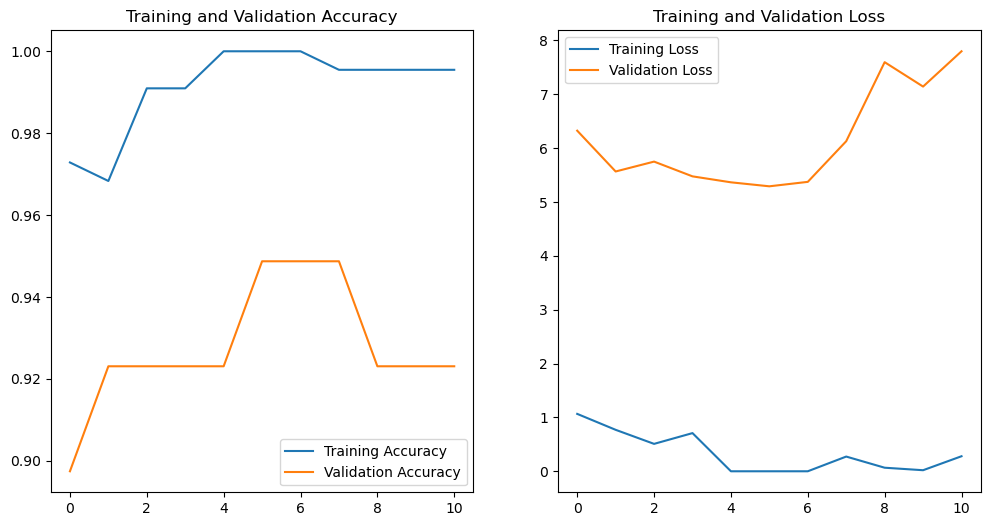

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

# Plot training  and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

**Accuracy**

- Training accuracy rises quickly and reaches ~99–100% by mid-training, while validation accuracy peaks around 92–95% and then plateaus.  
- The persistent gap between training and validation accuracy indicates overfitting: the classifier memorizes training features but does not gain comparable generalization.

**Loss**

- Training loss drops to near zero in the middle of training, then shows some rebound late.  
- Validation loss is large and increases over epochs despite fairly high validation accuracy. This suggests that the model becomes overconfident on the training set.


Like in Model 1, the accuracy and loss curves show typical behaviour for a small and complex dataset. The validation curves here are noticeably smoother and more stable, but the persistent gap between training and validation still indicates overfitting.

### Test Set Evaluation

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


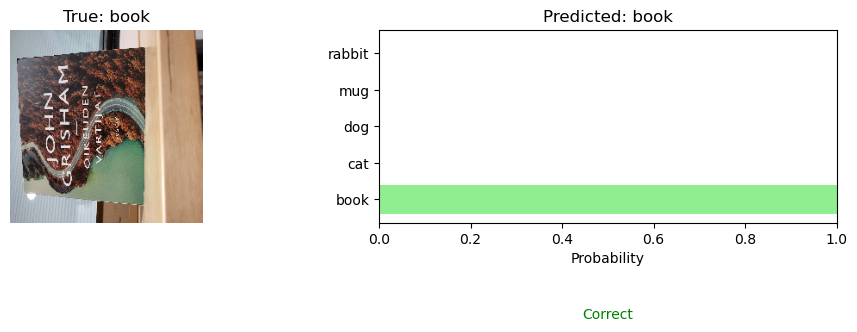

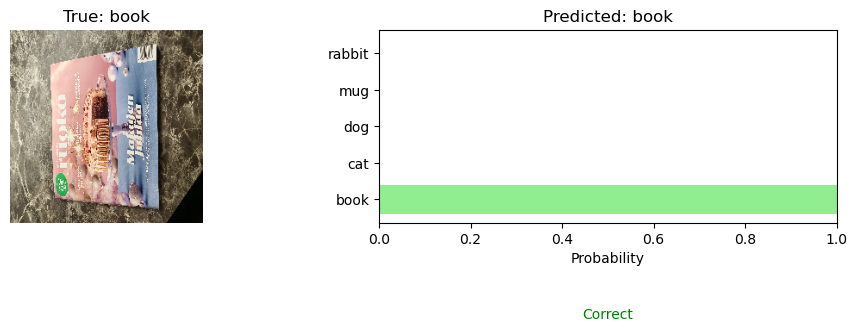

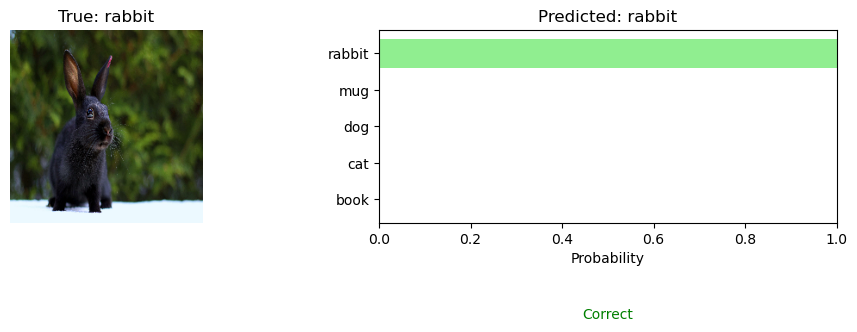

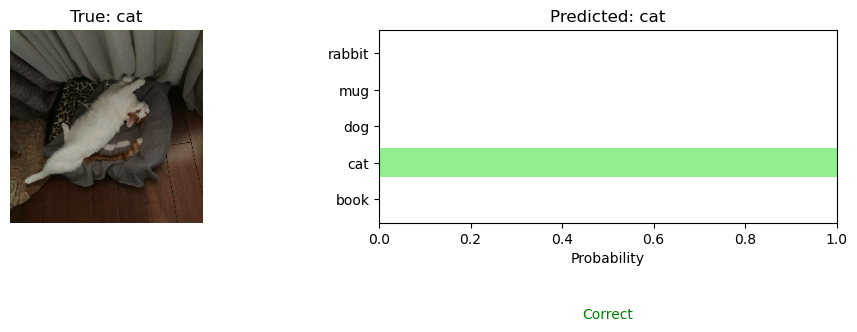

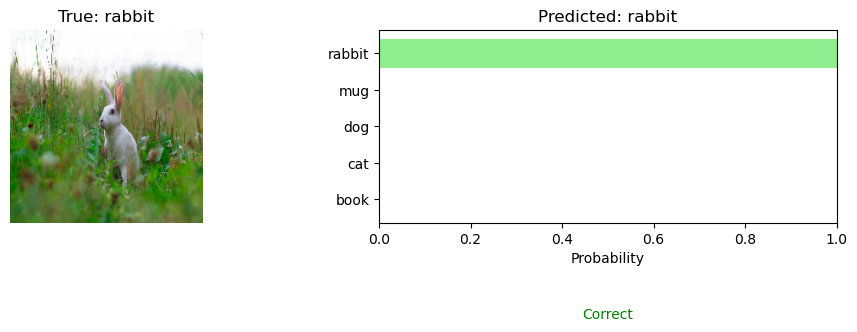

In [ ]:
import random

# Get a batch of test images from one batch
test_images, test_labels = next(iter(test_ds.take(1)))

# Preprocess images for VGG16, extract features and run the classifier model.
preprocessed = vgg_preprocess(test_images.numpy())
vgg_features = vgg.predict(preprocessed)
vgg_features_flat = vgg_features.reshape((vgg_features.shape[0], -1))

# Get predictions and convert to labels
predicted_probs = model.predict(vgg_features_flat)
true_labels = test_labels.numpy()
predicted_labels = np.argmax(predicted_probs, axis=1)

def deprocess_vgg(x):
    x = x.copy()
    if x.ndim == 4:
        # add means in BGR order then convert to RGB
        means = np.array([103.939, 116.779, 123.68], dtype=x.dtype)
        x += means.reshape((1,1,1,3))
        x = x[..., ::-1]  # BGR -> RGB
        x = np.clip(x, 0, 255).astype('uint8')
        return x
    else:
        means = np.array([103.939, 116.779, 123.68], dtype=x.dtype)
        x += means.reshape((1,1,3))
        x = x[..., ::-1]
        return np.clip(x, 0, 255).astype('uint8')

def plot_images_with_vgg(classifier_model, vgg_base, test_ds, class_names, vgg_preprocess):
    y_pred = []
    x_images = []
    x_preprocessed = []  
    y_true = []

    # Extract features and predictions for the entire test dataset
    for images, labels in test_ds:
        imgs = images.numpy()
        pre = vgg_preprocess(imgs)
        feats = vgg_base.predict(pre)
        feats_flat = feats.reshape((feats.shape[0], -1))
        preds = classifier_model.predict(feats_flat)
        y_pred.extend(preds)
        x_images.extend(imgs)
        x_preprocessed.extend(pre)
        y_true.extend(labels.numpy())
        
    y_pred = np.array(y_pred)
    x_images = np.array(x_images)
    x_preprocessed = np.array(x_preprocessed)
    y_true = np.array(y_true)

    # Convert predicted probabilities to integer labels for confusion matrix
    preds_labels = np.argmax(y_pred, axis=1)
    

    # Random 5 samples
    num_samples = 5
    random_indices = random.sample(range(len(x_images)), num_samples)

    for i in random_indices:
        plt.figure(figsize=(10, 4))

        # LEFT: image
        plt.subplot(1, 2, 1)
        try:
            img_to_show = deprocess_vgg(x_preprocessed[i])   # use stored preprocessed image
        except Exception:
            # fallback: if preprocessed not available, use original and convert scale if needed
            img = x_images[i]
            if img.dtype.kind == 'f' and img.max() <= 1.0:
                img = (img * 255).astype('uint8')
            img_to_show = img.astype('uint8')
        plt.imshow(img_to_show)
        true_class = class_names[int(y_true[i])]
        plt.title(f"True: {true_class}")
        plt.axis("off")

        # RIGHT: bar chart of predicted probabilities
        plt.subplot(1, 2, 2)
        pred_prob = y_pred[i]
        predicted_class = class_names[preds_labels[i]]

        # color bars: mark correct class green
        colors = [
            "lightgreen" if class_names[j] == true_class else "skyblue"
            for j in range(len(class_names))
        ]

        plt.barh(class_names, pred_prob, color=colors)
        plt.xlabel("Probability")
        plt.title(f"Predicted: {predicted_class}")
        plt.xlim([0, 1])

        # Add Correct/Incorrect label
        if predicted_class != true_class:
            plt.text(0.5, -0.5, "Incorrect", color="red",
                     ha="center", transform=plt.gca().transAxes)
        else:
            plt.text(0.5, -0.5, "Correct", color="green",
                     ha="center", transform=plt.gca().transAxes)

        plt.tight_layout()
        plt.show()

    
    return preds_labels, x_images, y_true, y_pred


# Call the function and capture outputs
y_pred, x_images, y_true, y_pred_probs = plot_images_with_vgg(model, vgg, test_ds, class_names, vgg_preprocess)

The test images shown were first transformed by VGG16 preprocessing (mean subtraction and BGR channel ordering), so they appeared noticeably different from the originals. This preprocessing aligns the inputs with the pretrained VGG features and likely contributes to the correct predictions in the selected examples. For easier readibility the images were deprocessed before plotting.

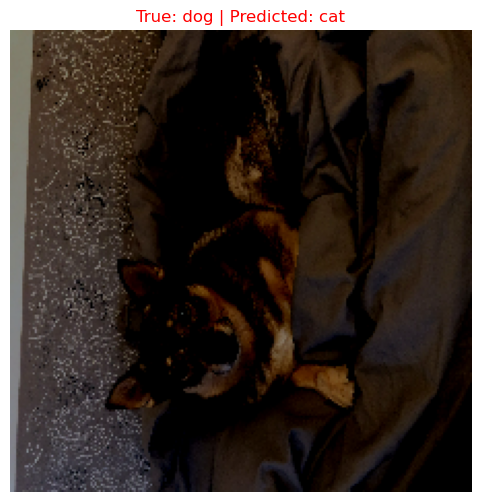

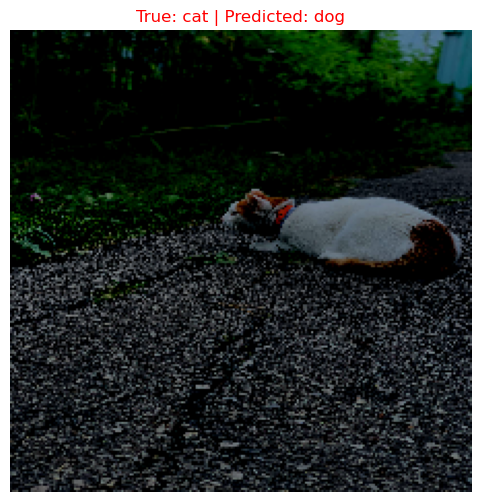

In [ ]:
# Plot misidentified samples
misidentified_indices = np.where(y_true != y_pred)[0]
if len(misidentified_indices) == 0:
    print("No misidentified samples found.")
else:
    pre_all = vgg_preprocess(x_images.astype('float32'))
    for i in misidentified_indices:
        plt.figure(figsize=(6, 6))
        if pre_all is not None:
            img_to_show = deprocess_vgg(pre_all[i])
        else:
            img = x_images[i]
            if img.dtype.kind == 'f' and img.max() <= 1.0:
                img = (img * 255).astype('uint8')
            img_to_show = img.astype('uint8')

        plt.imshow(img_to_show)
        true_class = class_names[int(y_true[i])]
        predicted_class = class_names[y_pred[i]]
        plt.title(f"True: {true_class} | Predicted: {predicted_class}", color="red")
        plt.axis("off")
        plt.show()

The two incorrect predictions came from one dog image and one cat image, both showing the animals lying down. The poses made the dog and cat appear visually similar even to a human observer. This likely contributed to the model’s confusion. The reduced visibility of distinguishing features such as face shape, ear position or body proportions can make the classes harder to separate.

These errors highlight a common challenge in image classification. Ambiguous or overlapping visual features can lead to mislabeling. Especially when subjects are in similar positions or partially obscured.

### Confusion Matrix and Classification report

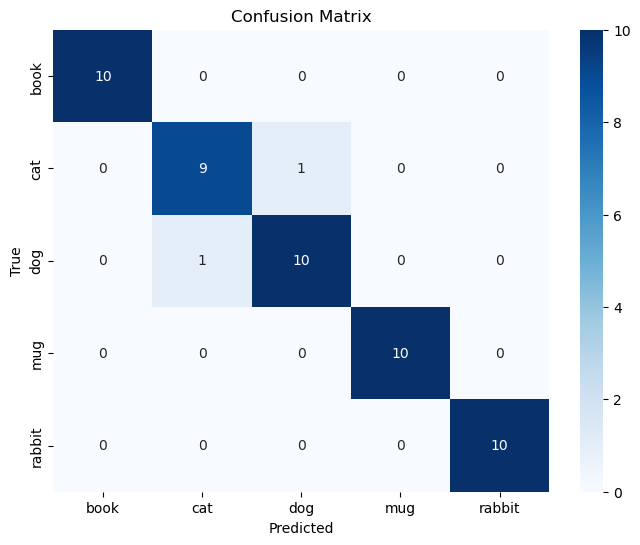

Classification report:

              precision    recall  f1-score   support

        book     1.0000    1.0000    1.0000        10
         cat     0.9000    0.9000    0.9000        10
         dog     0.9091    0.9091    0.9091        11
         mug     1.0000    1.0000    1.0000        10
      rabbit     1.0000    1.0000    1.0000        10

    accuracy                         0.9608        51
   macro avg     0.9618    0.9618    0.9618        51
weighted avg     0.9608    0.9608    0.9608        51

book: accuracy 1.0000
cat: accuracy 0.9000
dog: accuracy 0.9091
mug: accuracy 1.0000
rabbit: accuracy 1.0000


In [46]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix')
plt.show()

print("Classification report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

per_class_acc = cm.diagonal() / cm.sum(axis=1)
for cls, a in zip(class_names, per_class_acc):
    print(f"{cls}: accuracy {a:.4f}")

- Dogs: 10 were correctly identified, 1 was misidentified  as a cat.
- Cats: 9 were correctly identified, 1 was misidentified  as a dog.

The model demonstrates excellent performance, especially on book, mug, and rabbit, with slightly lower but still strong accuracy on cat and dog.

### Comparison between Model 1 and Model 2

The table below shows the comparison between Model 1 (custom CNN model) and Model 2 (pretrained VGG16 feature extraction model).

|  | Model 1 | Model 2 |
| --- | --- | --- |
| Accuracy | 54.9% | 96.1% |
| Loss behaviour | Training loss sometimes rebounces after dropping near zero and validation loss is unstable. | Similar pattern as in Model 1 but less rebouncing and more stable. |
| Validation curves | Noisier validation curves. | Smoother and steadier validation curves. |
| Overfitting/Generalization | Shows strong overfitting. Large gap between train and validation and low training loss and higher validation loss. | No effect. High performance on training, limited additional generalization on validation/test. |


Model 2 has smoother validation that suggests more stable optimization, but neither model achieves notably better generalization in current setup. The accuracy in Model 2 is significantly higher.

### Conclusion

Model 2, which uses VGG16 for feature extraction achieves noticeably higher raw accuracy on the dataset than the custom CNN used in Model 1 and its validation curves are smoother and more stable. However, both models show clear signs of overfitting with very high training accuracy and a persistent gap between train and validation.